# Fake News Detection: Data Analysis, Statistical Insights & Model Comparison

This notebook analyzes the dataset with **Pandas and NumPy**, explores descriptive statistics and label distributions, preprocesses text, and evaluates five machine-learning classifiers using the same train/test split.

> Dataset path: update the path below if your CSV is stored elsewhere. The expected columns are `label` and one or more of `title`, `author`, `text`, or `content`. Labels are assumed to be `1 = Fake` and `0 = Real`, as in the original notebook.

In [ ]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
import nltk

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

nltk.download('stopwords', quiet=True)
STOP_WORDS = set(stopwords.words('english'))
ps = PorterStemmer()
RANDOM_STATE = 42


In [ ]:
fake = pd.read_csv("Fake.csv")
true = pd.read_csv("True.csv")

fake["label"] = 1
true["label"] = 0

news_df = pd.concat([fake, true], axis=0)

news_df = news_df.sample(frac=1, random_state=42).reset_index(drop=True)

news_df.head()

,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",1
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",0
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",0
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",1
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",0


## 1. Data quality checks and Pandas analysis

In [ ]:
# Data types, missingness, duplicate records, and basic descriptive summaries
display(news_df.info())
display(news_df.describe(include='all').transpose())
print('Missing values per column:')
display(news_df.isna().sum().sort_values(ascending=False))
print('Duplicate rows:', news_df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.7+ MB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
title,44898,38729,Factbox: Trump fills top jobs for his administ...,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
text,44898,38646,,627,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subject,44898,8,politicsNews,11272,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,44898,2397,"December 20, 2017",182,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,44898.0,NaN,NaN,NaN,0.522985,0.499477,0.0,0.0,1.0,1.0,1.0


Missing values per column:


,0
title,0
text,0
subject,0
date,0
label,0


Duplicate rows: 209


In [ ]:
# Clean nulls in the text-related fields and label column
for col in ['title', 'author', 'text', 'content']:
    if col in news_df.columns:
        news_df[col] = news_df[col].fillna('')

if 'label' not in news_df.columns:
    raise ValueError("Dataset must contain a 'label' column.")

news_df['label'] = pd.to_numeric(news_df['label'], errors='coerce')
news_df = news_df.dropna(subset=['label']).copy()
news_df['label'] = news_df['label'].astype(int)

# Build one text field, prioritizing available title/author/text fields.
text_parts = [c for c in ['author', 'title', 'text', 'content'] if c in news_df.columns]
if not text_parts:
    raise ValueError("No text column found (expected title, author, text, or content).")
news_df['raw_content'] = news_df[text_parts].astype(str).agg(' '.join, axis=1)
news_df['raw_content'] = news_df['raw_content'].str.strip()

print('Rows after basic cleaning:', len(news_df))
display(news_df[['raw_content', 'label']].head())


Rows after basic cleaning: 44898


,raw_content,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,1
1,Trump drops Steve Bannon from National Securit...,0
2,Puerto Rico expects U.S. to lift Jones Act shi...,0
3,OOPS: Trump Just Accidentally Confirmed He Lea...,1
4,Donald Trump heads for Scotland to reopen a go...,0


,count,percentage
label,,
0,21417,47.7
1,23481,52.3


Label mean: 0.5229854336496058
Label variance: 0.24947722637334396
Label standard deviation: 0.4994769527949653


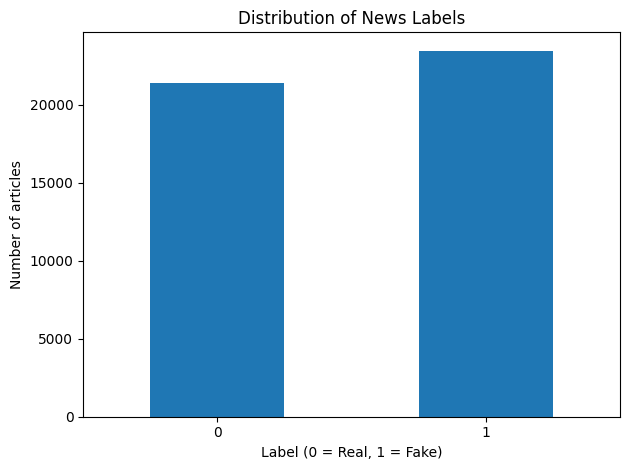

In [ ]:
# Label distribution: Pandas + NumPy summary statistics
label_counts = news_df['label'].value_counts().sort_index()
label_percent = news_df['label'].value_counts(normalize=True).sort_index() * 100

label_summary = pd.DataFrame({
    'count': label_counts,
    'percentage': label_percent.round(2)
})
display(label_summary)

print('Label mean:', np.mean(news_df['label']))
print('Label variance:', np.var(news_df['label'], ddof=1))
print('Label standard deviation:', np.std(news_df['label'], ddof=1))

ax = label_counts.plot(kind='bar', rot=0, title='Distribution of News Labels')
ax.set_xlabel('Label (0 = Real, 1 = Fake)')
ax.set_ylabel('Number of articles')
plt.tight_layout()
plt.show()


In [ ]:
# Text-length statistics (characters and word counts)
news_df['character_count'] = news_df['raw_content'].str.len()
news_df['word_count'] = news_df['raw_content'].str.split().str.len()

display(news_df.groupby('label')[['character_count', 'word_count']].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
))

# NumPy quantiles and summary statistics for the overall word-count distribution
word_counts = news_df['word_count'].to_numpy()
print('Word count mean:', np.mean(word_counts))
print('Word count median:', np.median(word_counts))
print('Word count std:', np.std(word_counts, ddof=1))
print('Word count quantiles (25%, 50%, 75%, 90%):', np.quantile(word_counts, [0.25, 0.5, 0.75, 0.90]))


character_count                                              word_count  \
                count         mean  median          std min    max      count   
label                                                                           
0               21417  2447.557314  2285.0  1684.398515  30  29848      21417   
1               23481  2641.923726  2258.0  2533.792006  29  51893      23481   

                                                
             mean median         std min   max  
label                                           
0      395.594574  369.0  273.948006   4  5181  
1      437.930710  378.0  408.555516   2  8148

Word count mean: 417.7357566038576
Word count median: 375.0
Word count std: 351.48077655206026
Word count quantiles (25%, 50%, 75%, 90%): [216. 375. 526. 758.]


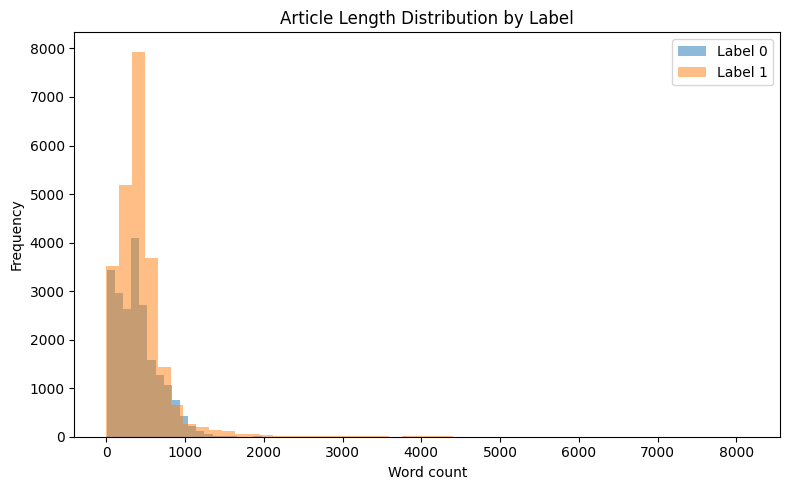

In [ ]:
# Plot word counts by label
plt.figure(figsize=(8, 5))
for label_value, group in news_df.groupby('label'):
    plt.hist(group['word_count'], bins=50, alpha=0.5, label=f'Label {label_value}')
plt.xlabel('Word count')
plt.ylabel('Frequency')
plt.title('Article Length Distribution by Label')
plt.legend()
plt.tight_layout()
plt.show()


## 2. Text preprocessing

Remove non-alphabetic characters, lowercase, remove stop words, and stem tokens. This retains the original notebook's Porter stemming approach.

In [ ]:
def stemming(content):
    content = re.sub(r'[^a-zA-Z]', ' ', content).lower()
    tokens = content.split()
    tokens = [ps.stem(word) for word in tokens if word not in STOP_WORDS]
    return ' '.join(tokens)

news_df['processed_content'] = news_df['raw_content'].apply(stemming)
display(news_df[['raw_content', 'processed_content', 'label']].head())


,raw_content,processed_content,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,ben stein call th circuit court commit coup ta...,1
1,Trump drops Steve Bannon from National Securit...,trump drop steve bannon nation secur council w...,0
2,Puerto Rico expects U.S. to lift Jones Act shi...,puerto rico expect u lift jone act ship restri...,0
3,OOPS: Trump Just Accidentally Confirmed He Lea...,oop trump accident confirm leak isra intellig ...,1
4,Donald Trump heads for Scotland to reopen a go...,donald trump head scotland reopen golf resort ...,0


## 3. Train/test split and TF-IDF

The vectorizer is fitted **only on the training data** to avoid data leakage. The same split and features are used for all five models.

In [ ]:
X_text = news_df['processed_content'].values
y = news_df['label'].values

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

vectorizer = TfidfVectorizer(max_features=None)
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)
print('Vocabulary size:', len(vectorizer.vocabulary_))


Train shape: (35918, 81647)
Test shape: (8980, 81647)
Vocabulary size: 81647


## 4. Statistical modelling and machine-learning model comparison

We compare five classifiers:
1. Logistic Regression
2. Multinomial Naive Bayes
3. Linear Support Vector Classifier (LinearSVC)
4. Random Forest
5. SGD Classifier

Metrics include accuracy, precision, recall, F1-score and ROC-AUC where a score/probability is available. These metrics are more informative than accuracy alone, particularly if the labels are imbalanced.

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Multinomial Naive Bayes': MultinomialNB(),
    'Linear SVC': LinearSVC(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    'SGD Classifier': SGDClassifier(loss='hinge', random_state=RANDOM_STATE, max_iter=1000, tol=1e-3)
}

results = []
fitted_models = {}
model_predictions = {}

for model_name, clf in models.items():
    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)
    model_predictions[model_name] = pred
    fitted_models[model_name] = clf

    score_values = None
    try:
        if hasattr(clf, 'predict_proba'):
            score_values = clf.predict_proba(X_test)[:, 1]
        elif hasattr(clf, 'decision_function'):
            score_values = clf.decision_function(X_test)
        auc = roc_auc_score(y_test, score_values) if score_values is not None else np.nan
    except Exception:
        auc = np.nan

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1 Score': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': auc
    })

results_df = pd.DataFrame(results).sort_values('F1 Score', ascending=False).reset_index(drop=True)
display(results_df.style.format({c: '{:.4f}' for c in results_df.columns if c != 'Model'}))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Linear SVC,0.9945,0.9957,0.9938,0.9948,0.9998
1,Random Forest,0.9938,0.9947,0.9934,0.9940,0.9997
2,SGD Classifier,0.9902,0.9936,0.9876,0.9906,0.9995
3,Logistic Regression,0.9864,0.9901,0.9838,0.9870,0.9990
4,Multinomial Naive Bayes,0.9353,0.9296,0.9480,0.9387,0.9822


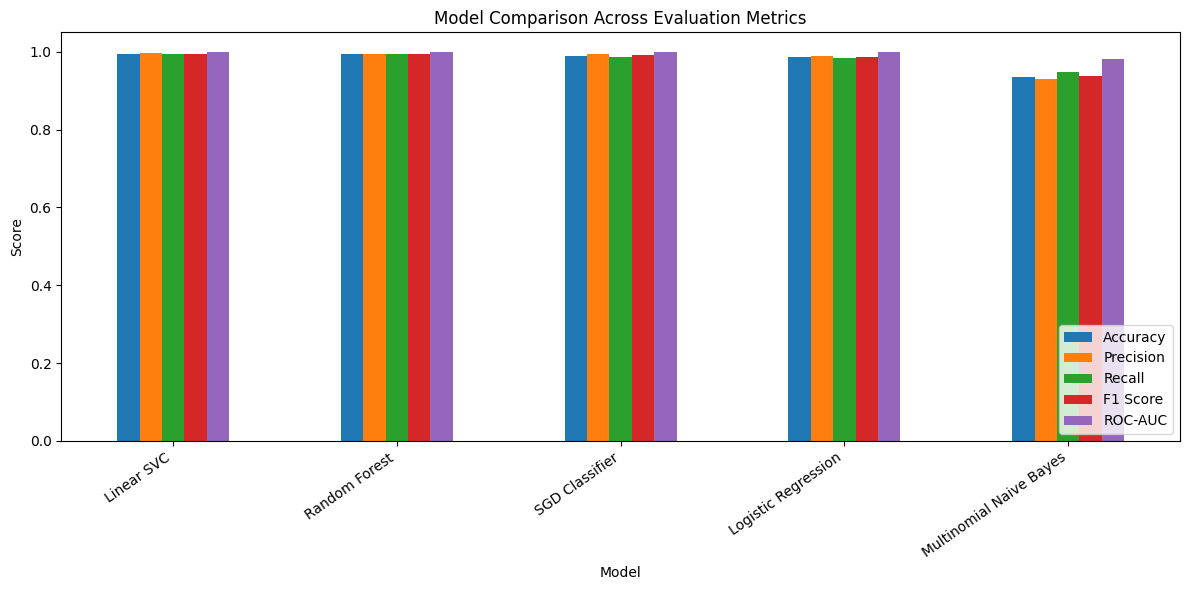

In [21]:
# Visual comparison of key evaluation metrics
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
results_df.set_index('Model')[metrics_to_plot].plot(kind='bar', figsize=(12, 6))
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.title('Model Comparison Across Evaluation Metrics')
plt.xticks(rotation=35, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


Best model based on test F1 score: Linear SVC
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      4284
           1       1.00      0.99      0.99      4696

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



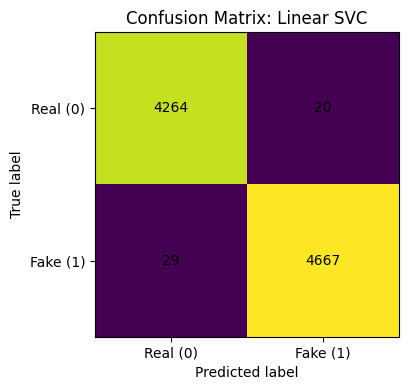

In [ ]:
# Detailed report and confusion matrix for the best model by F1 score
best_model_name = results_df.iloc[0]['Model']
best_model = fitted_models[best_model_name]
best_predictions = model_predictions[best_model_name]

print('Best model based on test F1 score:', best_model_name)
print(classification_report(y_test, best_predictions, zero_division=0))

cm = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title(f'Confusion Matrix: {best_model_name}')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks([0, 1], ['Real (0)', 'Fake (1)'])
plt.yticks([0, 1], ['Real (0)', 'Fake (1)'])
for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, str(value), ha='center', va='center')
plt.tight_layout()
plt.show()


## 5. Training vs testing performance (overfitting check)

In [ ]:
# Compare train/test scores for the selected model
train_pred = best_model.predict(X_train)
test_pred = best_model.predict(X_test)

train_metrics = {
    'Accuracy': accuracy_score(y_train, train_pred),
    'F1 Score': f1_score(y_train, train_pred, zero_division=0)
}
test_metrics = {
    'Accuracy': accuracy_score(y_test, test_pred),
    'F1 Score': f1_score(y_test, test_pred, zero_division=0)
}
display(pd.DataFrame({'Train': train_metrics, 'Test': test_metrics}))


,Train,Test
Accuracy,0.999610,0.994543
F1 Score,0.999627,0.994778


## 6. Feature inspection (most informative TF-IDF features for Logistic Regression)

In [ ]:
# Coefficients are available for Logistic Regression; positive coefficients indicate class 1.
lr_model = fitted_models['Logistic Regression']
feature_names = np.array(vectorizer.get_feature_names_out())
coefficients = lr_model.coef_[0]

top_fake_idx = np.argsort(coefficients)[-20:][::-1]
top_real_idx = np.argsort(coefficients)[:20]

feature_insights = pd.DataFrame({
    'More associated with Fake (label 1)': feature_names[top_fake_idx],
    'More associated with Real (label 0)': feature_names[top_real_idx]
})
display(feature_insights)


,More associated with Fake (label 1),More associated with Real (label 0)
0,via,reuter
1,video,said
2,us,washington
3,imag,wednesday
4,gop,tuesday
5,read,thursday
6,hillari,friday
7,mr,monday
8,com,minist
9,featur,nov


## 7. Predict on a custom news article

In [ ]:
def predict_news(news_text, model_name=best_model_name):
    processed = stemming(news_text)
    features = vectorizer.transform([processed])
    prediction = fitted_models[model_name].predict(features)[0]
    label_text = 'Fake News' if prediction == 1 else 'Real News'
    return label_text, prediction

sample_text = "Paste a news article here to test the model."
print(predict_news(sample_text))


('Fake News', np.int64(1))


## 8. Conclusion

Review `results_df` to determine which model performed best on the held-out test set. Do not treat the scores as proof of truthfulness: models learn patterns in the dataset and may be affected by topic, source, dataset bias, or distribution shifts. A test score is not a substitute for fact-checking.

**Analysis covered:** Pandas data inspection and cleaning, NumPy summary statistics and quantiles, label/text-length distribution plots, TF-IDF text representation, five classification models, evaluation metrics, confusion matrix, train/test performance and feature inspection.